## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Daniel Felipe Buitrago Gonzalez" # @param {"type":"string"}
carnet = 1000116039 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa debe administrar tareas técnicas según su prioridad y conectar varios dispositivos 
utilizando la menor cantidad total de cable.

## 2) Requerimientos **[2 pts]**

Requerimientos Funcionales (RF)

RF1. Registrar las tareas con código, nombre y prioridad respectivamente.
RF2. Construir cola de prioridad usando Max-Heap.
RF3. Mostrar el arreglo inicial y el Max-Heap resultante.
RF4. Representar gráficamente el árbol Max-Heap.
RF5. Procesar las dos tareas de mayor prioridad.
RF6. Extraer y mostrar tarea procesada y Heap resultante.
RF8. Insertar nuevas tareas manteniendo la propiedad del Max-Heap.
RF9. Registrar los dispositivos con sus coordenadas.

Requerimientos No Funcionales (RNF)

RNF1. No usar heapq.
RNF2. No implementar funciones de librerias que calculen directamente el MST.
RNF3. Implementar el algoritmo de Kruskal para encontrar el árbol de expansión mínima.

 

## 3) Historias de usuario **[2 pts]**

HU01: Como administrador quiero gestionar las tareas tecnicas según su prioridad y varios dispositvos para utilizar la menjor cantidad total de cable.
HU02: Como programador quiero procesar tareas implementando un EXTRACT-MAX para procesar las 2 tareas de mayor prioridad.
HU03: Como segundo programador quiero saber la cantidad total del cable implementando Kruskal para conectar los 6 dispositivos



## 4) Diagramas de flujo **[5 pts]**

![D. Flujo.png](<attachment:D. Flujo.png>)
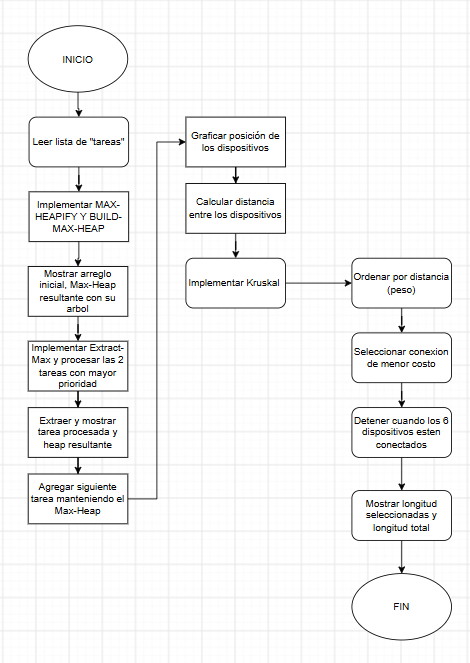

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica


## 6) Código funcional **[15 pts]**



ARREGLO INICIAL:
['T01', 'Configurar servidor', 6]
['T02', 'Reparar sensor', 10]
['T03', 'Actualizar software', 4]
['T04', 'Revisar cámara', 8]
['T05', 'Generar respaldo', 3]
['T06', 'Configurar alarma', 7]

MAX-HEAP RESULTANTE:
['T02', 'Reparar sensor', 10]
['T04', 'Revisar cámara', 8]
['T06', 'Configurar alarma', 7]
['T01', 'Configurar servidor', 6]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]


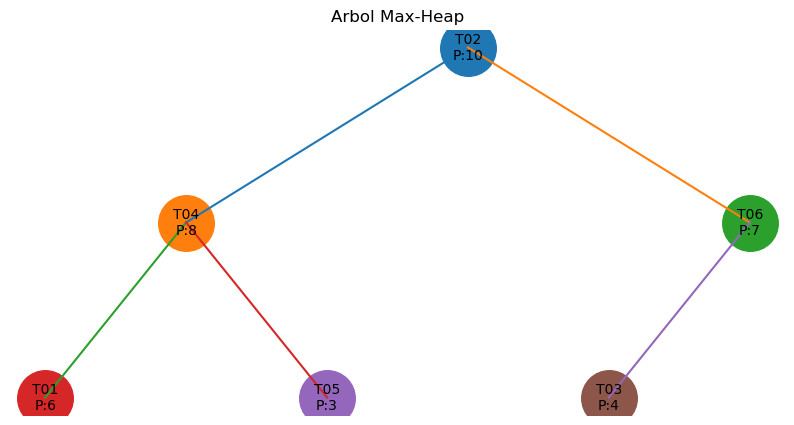


PROCESAMIENTO DE TAREAS:

Tarea procesada: ['T02', 'Reparar sensor', 10]
Heap resultante:
['T04', 'Revisar cámara', 8]
['T01', 'Configurar servidor', 6]
['T06', 'Configurar alarma', 7]
['T03', 'Actualizar software', 4]
['T05', 'Generar respaldo', 3]

Tarea procesada: ['T04', 'Revisar cámara', 8]
Heap resultante:
['T06', 'Configurar alarma', 7]
['T01', 'Configurar servidor', 6]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]

HEAP DESPUES DE INSERTAR T07:
['T07', 'Falla en sistema contra incendios', 12]
['T06', 'Configurar alarma', 7]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]
['T01', 'Configurar servidor', 6]


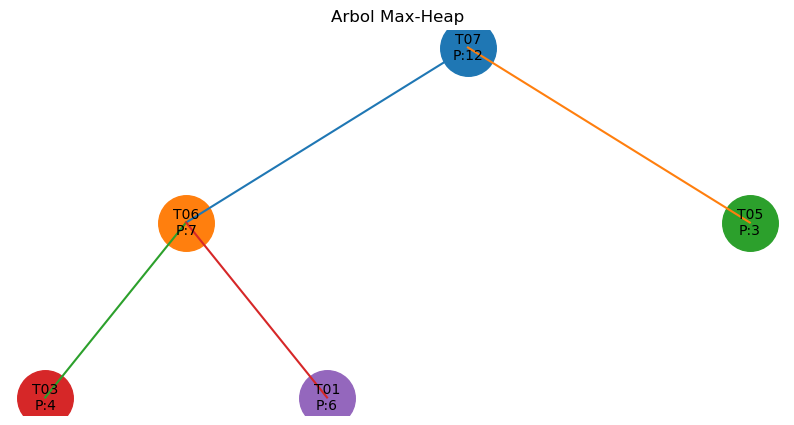


DISTANCIAS ENTRE DISPOSITIVOS:
A - B : 5.1
A - C : 5.39
A - D : 10.0
A - E : 11.05
A - F : 13.93
B - C : 5.0
B - D : 5.83
B - E : 6.0
B - F : 8.94
C - D : 6.08
C - E : 9.85
C - F : 11.0
D - E : 5.83
D - F : 5.1
E - F : 4.47


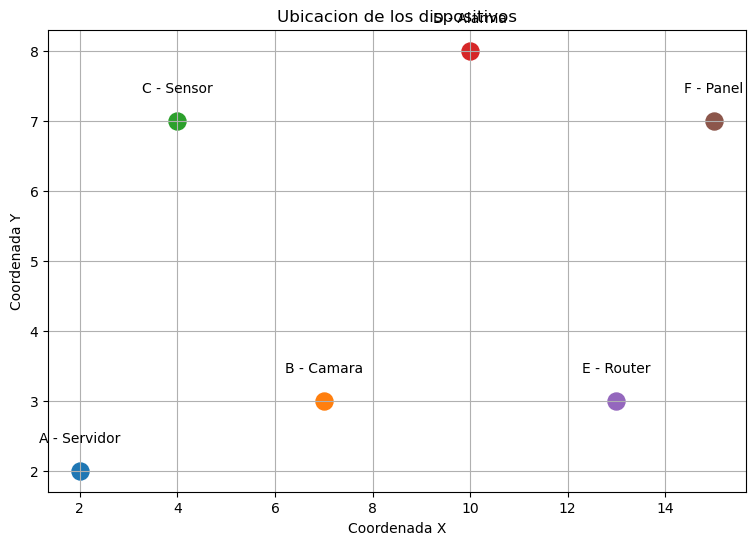


CONEXIONES DEL ARBOL DE EXPANSION MINIMA:
E - F : 4.47
B - C : 5.0
A - B : 5.1
D - F : 5.1
B - D : 5.83

LONGITUD TOTAL DE CABLE: 25.5


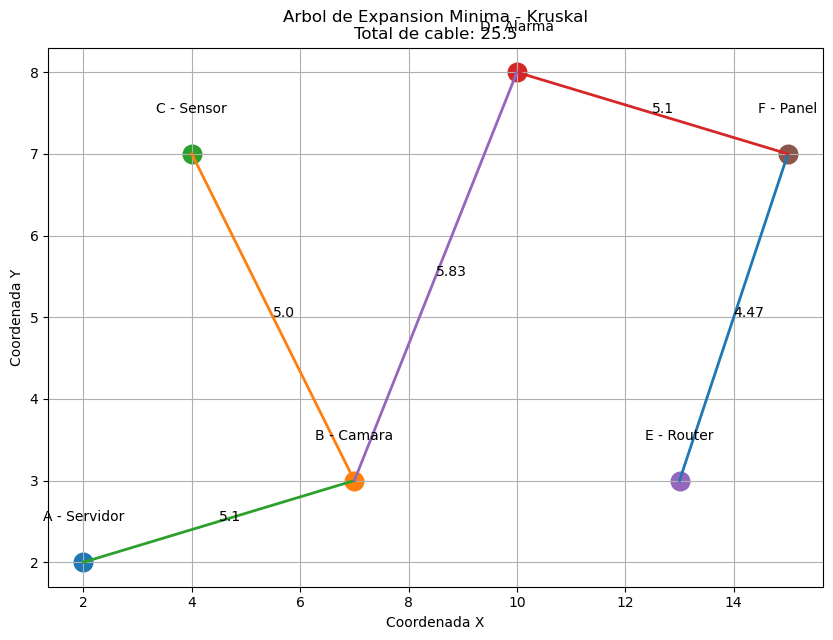

In [3]:

import math
import matplotlib.pyplot as plt
 
tareas = [
    ["T01", "Configurar servidor", 6],
    ["T02", "Reparar sensor", 10],
    ["T03", "Actualizar software", 4],
    ["T04", "Revisar cámara", 8],
    ["T05", "Generar respaldo", 3],
    ["T06", "Configurar alarma", 7]
]
 
def max_heapify(heap, i, n):
    mayor = i
    izquierda = 2 * i + 1
    derecha = 2 * i + 2
 
    if izquierda < n and heap[izquierda][2] > heap[mayor][2]:
        mayor = izquierda
 
    if derecha < n and heap[derecha][2] > heap[mayor][2]:
        mayor = derecha
 
    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, n)
 
 
def build_max_heap(heap):
    n = len(heap)
 
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, i, n)
 
 
def mostrar_heap(heap):
    for tarea in heap:
        print(tarea)
 
 
def dibujar_heap(heap):
    plt.figure(figsize=(10, 5))
 
    posiciones = {}
 
    for i, tarea in enumerate(heap):
        nivel = int(math.log2(i + 1))
        posicion = i - (2 ** nivel - 1)
 
        x = (posicion + 0.5) / (2 ** nivel)
        y = -nivel
 
        posiciones[i] = (x, y)
 
    for i in range(len(heap)):
        izquierda = 2 * i + 1
        derecha = 2 * i + 2
 
        if izquierda < len(heap):
            plt.plot(
                [posiciones[i][0], posiciones[izquierda][0]],
                [posiciones[i][1], posiciones[izquierda][1]]
            )
 
        if derecha < len(heap):
            plt.plot(
                [posiciones[i][0], posiciones[derecha][0]],
                [posiciones[i][1], posiciones[derecha][1]]
            )
 
    for i, tarea in enumerate(heap):
        x, y = posiciones[i]
 
        plt.scatter(x, y, s=1600)
        plt.text(
            x, y,
            f"{tarea[0]}\nP:{tarea[2]}",
            ha="center", va="center"
        )
 
    plt.title("Arbol Max-Heap")
    plt.axis("off")
    plt.show()
 
 
print("ARREGLO INICIAL:")
mostrar_heap(tareas)
 
build_max_heap(tareas)
 
print("\nMAX-HEAP RESULTANTE:")
mostrar_heap(tareas)
 
dibujar_heap(tareas)
 
def extract_max(heap):
    if len(heap) == 0:
        return None
 
    mayor = heap[0]
    ultimo = heap.pop()
 
    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, 0, len(heap))
 
    return mayor
 
 
print("\nPROCESAMIENTO DE TAREAS:")
 
for i in range(2):
    tarea = extract_max(tareas)
 
    print("\nTarea procesada:", tarea)
    print("Heap resultante:")
    mostrar_heap(tareas)
 
 
def insertar(heap, tarea):
    heap.append(tarea)
 
    i = len(heap) - 1
 
    while i > 0:
        padre = (i - 1) // 2
 
        if heap[i][2] > heap[padre][2]:
            heap[i], heap[padre] = heap[padre], heap[i]
            i = padre
        else:
            break
 
 
nueva_tarea = [
    "T07",
    "Falla en sistema contra incendios",
    12
]
 
insertar(tareas, nueva_tarea)
 
print("\nHEAP DESPUES DE INSERTAR T07:")
mostrar_heap(tareas)
 
dibujar_heap(tareas)
 

 
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Camara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7)
}
 
 
def calcular_distancia(p1, p2):
    x1, y1 = dispositivos[p1][1], dispositivos[p1][2]
    x2, y2 = dispositivos[p2][1], dispositivos[p2][2]
 
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
 
 
aristas = []
 
ids = list(dispositivos.keys())
 
print("\nDISTANCIAS ENTRE DISPOSITIVOS:")
 
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a = ids[i]
        b = ids[j]
 
        distancia = calcular_distancia(a, b)
 
        aristas.append((distancia, a, b))
 
        print(a, "-", b, ":", round(distancia, 2))
 
 
 
plt.figure(figsize=(9, 6))
 
for identificador, datos in dispositivos.items():
    nombre, x, y = datos
 
    plt.scatter(x, y, s=150)
 
    plt.text(
        x, y + 0.4,
        identificador + " - " + nombre,
        ha="center"
    )
 
plt.title("Ubicacion de los dispositivos")
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.grid()
plt.show()
 

def buscar(padre, nodo):
    if padre[nodo] != nodo:
        padre[nodo] = buscar(padre, padre[nodo])
 
    return padre[nodo]
 
 
def kruskal(dispositivos, aristas):
 
    padre = {}
 
    for nodo in dispositivos:
        padre[nodo] = nodo
 
    aristas_ordenadas = sorted(aristas)
 
    mst = []
    total = 0
 
    for peso, origen, destino in aristas_ordenadas:
 
        raiz1 = buscar(padre, origen)
        raiz2 = buscar(padre, destino)
 
        if raiz1 != raiz2:
 
            mst.append((origen, destino, peso))
            total += peso
 
            padre[raiz1] = raiz2
 
        if len(mst) == len(dispositivos) - 1:
            break
 
    return mst, total
 
 
mst, total = kruskal(dispositivos, aristas)
 
print("\nCONEXIONES DEL ARBOL DE EXPANSION MINIMA:")
 
for origen, destino, peso in mst:
    print(
        origen, "-", destino,
        ":", round(peso, 2)
    )
 
print("\nLONGITUD TOTAL DE CABLE:", round(total, 2))
 
 
plt.figure(figsize=(10, 7))
 
 
for identificador, datos in dispositivos.items():
 
    nombre, x, y = datos
 
    plt.scatter(x, y, s=180)
 
    plt.text(
        x, y + 0.5,
        identificador + " - " + nombre,
        ha="center"
    )
 
 
for origen, destino, peso in mst:
 
    x1 = dispositivos[origen][1]
    y1 = dispositivos[origen][2]
 
    x2 = dispositivos[destino][1]
    y2 = dispositivos[destino][2]
 
    plt.plot([x1, x2], [y1, y2], linewidth=2)
 
    medio_x = (x1 + x2) / 2
    medio_y = (y1 + y2) / 2
 
    plt.text(
        medio_x, medio_y,
        str(round(peso, 2)),
        fontsize=10
    )
 
 
plt.title(
    "Arbol de Expansion Minima - Kruskal\n"
    + "Total de cable: "
    + str(round(total, 2))
)
 
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.grid()
plt.show()



## 7) Tests aplicados **[15 pts]**

ARREGLO INICIAL:
['T01', 'Configurar servidor', 6]
['T02', 'Reparar sensor', 10]
['T03', 'Actualizar software', 4]
['T04', 'Revisar cámara', 8]
['T05', 'Generar respaldo', 3]
['T06', 'Configurar alarma', 7]

MAX-HEAP RESULTANTE:
['T02', 'Reparar sensor', 10]
['T04', 'Revisar cámara', 8]
['T06', 'Configurar alarma', 7]
['T01', 'Configurar servidor', 6]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]


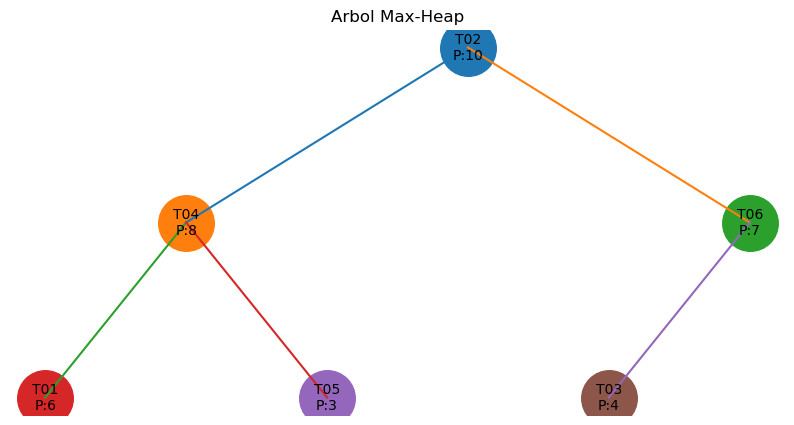


PROCESAMIENTO DE TAREAS:

Tarea procesada: ['T02', 'Reparar sensor', 10]
Heap resultante:
['T04', 'Revisar cámara', 8]
['T01', 'Configurar servidor', 6]
['T06', 'Configurar alarma', 7]
['T03', 'Actualizar software', 4]
['T05', 'Generar respaldo', 3]

Tarea procesada: ['T04', 'Revisar cámara', 8]
Heap resultante:
['T06', 'Configurar alarma', 7]
['T01', 'Configurar servidor', 6]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]

HEAP DESPUES DE INSERTAR T07:
['T07', 'Falla en sistema contra incendios', 12]
['T06', 'Configurar alarma', 7]
['T05', 'Generar respaldo', 3]
['T03', 'Actualizar software', 4]
['T01', 'Configurar servidor', 6]


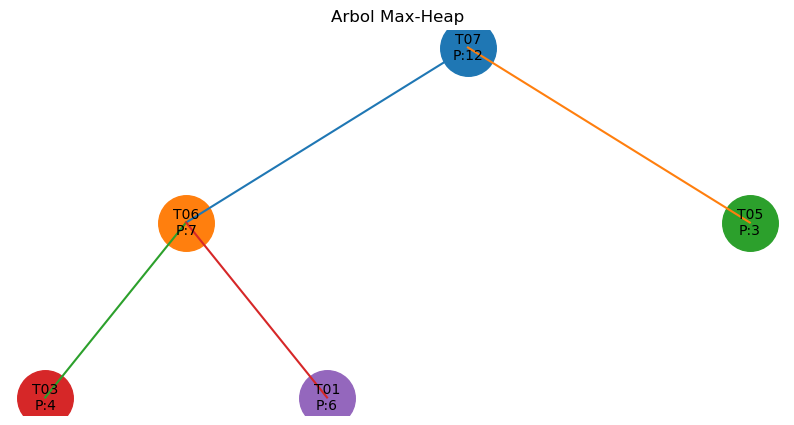


DISTANCIAS ENTRE DISPOSITIVOS:
A - B : 5.1
A - C : 5.39
A - D : 10.0
A - E : 11.05
A - F : 13.93
B - C : 5.0
B - D : 5.83
B - E : 6.0
B - F : 8.94
C - D : 6.08
C - E : 9.85
C - F : 11.0
D - E : 5.83
D - F : 5.1
E - F : 4.47


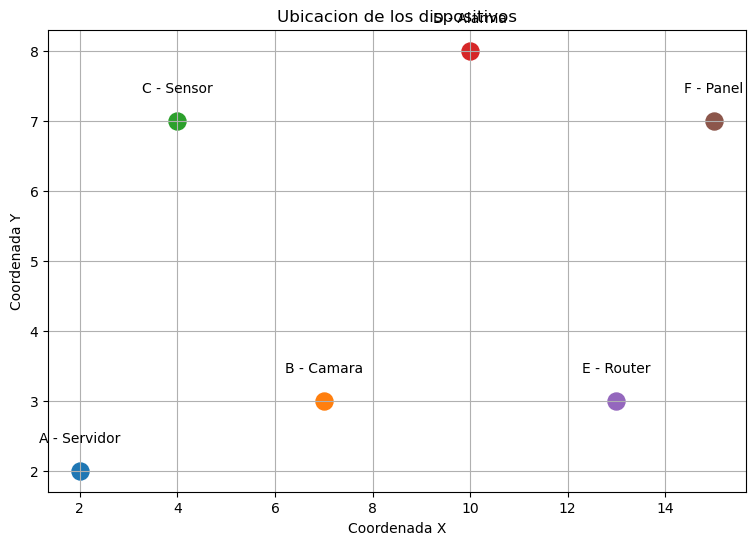


CONEXIONES DEL ARBOL DE EXPANSION MINIMA:
E - F : 4.47
B - C : 5.0
A - B : 5.1
D - F : 5.1
B - D : 5.83

LONGITUD TOTAL DE CABLE: 25.5


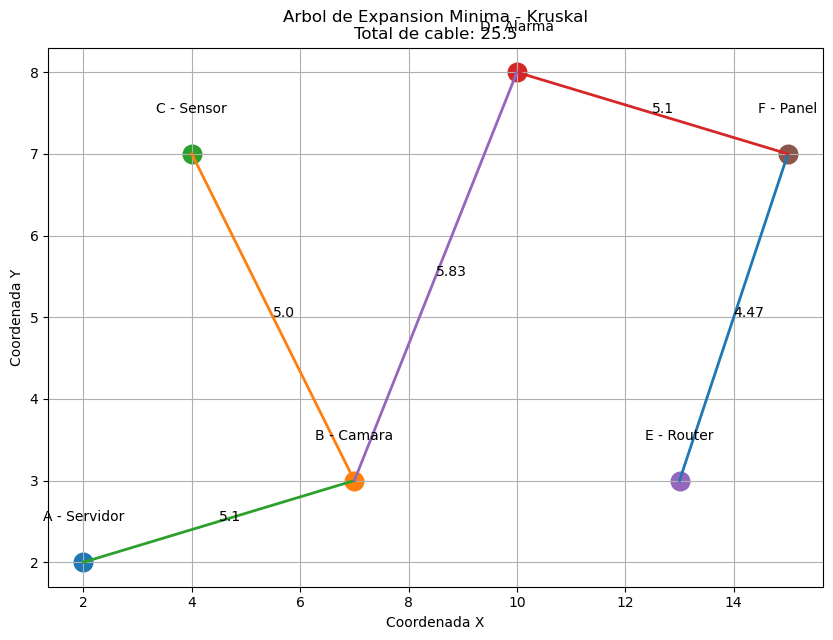

In [4]:

import math
import matplotlib.pyplot as plt
 
tareas = [
    ["T01", "Configurar servidor", 6],
    ["T02", "Reparar sensor", 10],
    ["T03", "Actualizar software", 4],
    ["T04", "Revisar cámara", 8],
    ["T05", "Generar respaldo", 3],
    ["T06", "Configurar alarma", 7]
]
 
def max_heapify(heap, i, n):
    mayor = i
    izquierda = 2 * i + 1
    derecha = 2 * i + 2
 
    if izquierda < n and heap[izquierda][2] > heap[mayor][2]:
        mayor = izquierda
 
    if derecha < n and heap[derecha][2] > heap[mayor][2]:
        mayor = derecha
 
    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, n)
 
 
def build_max_heap(heap):
    n = len(heap)
 
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, i, n)
 
 
def mostrar_heap(heap):
    for tarea in heap:
        print(tarea)
 
 
def dibujar_heap(heap):
    plt.figure(figsize=(10, 5))
 
    posiciones = {}
 
    for i, tarea in enumerate(heap):
        nivel = int(math.log2(i + 1))
        posicion = i - (2 ** nivel - 1)
 
        x = (posicion + 0.5) / (2 ** nivel)
        y = -nivel
 
        posiciones[i] = (x, y)
 
    for i in range(len(heap)):
        izquierda = 2 * i + 1
        derecha = 2 * i + 2
 
        if izquierda < len(heap):
            plt.plot(
                [posiciones[i][0], posiciones[izquierda][0]],
                [posiciones[i][1], posiciones[izquierda][1]]
            )
 
        if derecha < len(heap):
            plt.plot(
                [posiciones[i][0], posiciones[derecha][0]],
                [posiciones[i][1], posiciones[derecha][1]]
            )
 
    for i, tarea in enumerate(heap):
        x, y = posiciones[i]
 
        plt.scatter(x, y, s=1600)
        plt.text(
            x, y,
            f"{tarea[0]}\nP:{tarea[2]}",
            ha="center", va="center"
        )
 
    plt.title("Arbol Max-Heap")
    plt.axis("off")
    plt.show()
 
 
print("ARREGLO INICIAL:")
mostrar_heap(tareas)
 
build_max_heap(tareas)
 
print("\nMAX-HEAP RESULTANTE:")
mostrar_heap(tareas)
 
dibujar_heap(tareas)
 
def extract_max(heap):
    if len(heap) == 0:
        return None
 
    mayor = heap[0]
    ultimo = heap.pop()
 
    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, 0, len(heap))
 
    return mayor
 
 
print("\nPROCESAMIENTO DE TAREAS:")
 
for i in range(2):
    tarea = extract_max(tareas)
 
    print("\nTarea procesada:", tarea)
    print("Heap resultante:")
    mostrar_heap(tareas)
 
 
def insertar(heap, tarea):
    heap.append(tarea)
 
    i = len(heap) - 1
 
    while i > 0:
        padre = (i - 1) // 2
 
        if heap[i][2] > heap[padre][2]:
            heap[i], heap[padre] = heap[padre], heap[i]
            i = padre
        else:
            break
 
 
nueva_tarea = [
    "T07",
    "Falla en sistema contra incendios",
    12
]
 
insertar(tareas, nueva_tarea)
 
print("\nHEAP DESPUES DE INSERTAR T07:")
mostrar_heap(tareas)
 
dibujar_heap(tareas)
 

 
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Camara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7)
}
 
 
def calcular_distancia(p1, p2):
    x1, y1 = dispositivos[p1][1], dispositivos[p1][2]
    x2, y2 = dispositivos[p2][1], dispositivos[p2][2]
 
    return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
 
 
aristas = []
 
ids = list(dispositivos.keys())
 
print("\nDISTANCIAS ENTRE DISPOSITIVOS:")
 
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a = ids[i]
        b = ids[j]
 
        distancia = calcular_distancia(a, b)
 
        aristas.append((distancia, a, b))
 
        print(a, "-", b, ":", round(distancia, 2))
 
 
 
plt.figure(figsize=(9, 6))
 
for identificador, datos in dispositivos.items():
    nombre, x, y = datos
 
    plt.scatter(x, y, s=150)
 
    plt.text(
        x, y + 0.4,
        identificador + " - " + nombre,
        ha="center"
    )
 
plt.title("Ubicacion de los dispositivos")
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.grid()
plt.show()
 

def buscar(padre, nodo):
    if padre[nodo] != nodo:
        padre[nodo] = buscar(padre, padre[nodo])
 
    return padre[nodo]
 
 
def kruskal(dispositivos, aristas):
 
    padre = {}
 
    for nodo in dispositivos:
        padre[nodo] = nodo
 
    aristas_ordenadas = sorted(aristas)
 
    mst = []
    total = 0
 
    for peso, origen, destino in aristas_ordenadas:
 
        raiz1 = buscar(padre, origen)
        raiz2 = buscar(padre, destino)
 
        if raiz1 != raiz2:
 
            mst.append((origen, destino, peso))
            total += peso
 
            padre[raiz1] = raiz2
 
        if len(mst) == len(dispositivos) - 1:
            break
 
    return mst, total
 
 
mst, total = kruskal(dispositivos, aristas)
 
print("\nCONEXIONES DEL ARBOL DE EXPANSION MINIMA:")
 
for origen, destino, peso in mst:
    print(
        origen, "-", destino,
        ":", round(peso, 2)
    )
 
print("\nLONGITUD TOTAL DE CABLE:", round(total, 2))
 
 
plt.figure(figsize=(10, 7))
 
 
for identificador, datos in dispositivos.items():
 
    nombre, x, y = datos
 
    plt.scatter(x, y, s=180)
 
    plt.text(
        x, y + 0.5,
        identificador + " - " + nombre,
        ha="center"
    )
 
 
for origen, destino, peso in mst:
 
    x1 = dispositivos[origen][1]
    y1 = dispositivos[origen][2]
 
    x2 = dispositivos[destino][1]
    y2 = dispositivos[destino][2]
 
    plt.plot([x1, x2], [y1, y2], linewidth=2)
 
    medio_x = (x1 + x2) / 2
    medio_y = (y1 + y2) / 2
 
    plt.text(
        medio_x, medio_y,
        str(round(peso, 2)),
        fontsize=10
    )
 
 
plt.title(
    "Arbol de Expansion Minima - Kruskal\n"
    + "Total de cable: "
    + str(round(total, 2))
)
 
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.grid()
plt.show()

